### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_CPHVMVEELMBT


### Main

In [3]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
from matplotlib.patches import Rectangle

In [4]:
def export_movie_with_scalebar(
    movie: np.ndarray,
    output_path: str,
    fps: int = 20,
    actual_dt = 1/15.4,
    pixel_size_um: float = 1.0,
    scalebar_um: float = 10.0,
    font_size: int = 10,
    bar_height_px: int = 5,
    cmap: str = 'gray'
):
    """
    Export 3D grayscale movie as MP4 using matplotlib, with scalebar and timestamp overlay.

    Parameters:
    - movie: 3D NumPy array of shape (T, H, W), dtype=uint8
    - output_path: Output file path for MP4
    - fps: Frames per second
    - pixel_size_um: Microns per pixel
    - scalebar_um: Length of the scalebar in microns
    - font_size: Size of timestamp text
    - bar_height_px: Thickness of scalebar in image pixels
    - cmap: Colormap for display
    """
    assert movie.ndim == 3 and movie.dtype == np.uint8, "movie must be (T, H, W) uint8"
    T, H, W = movie.shape
    scalebar_length_px = int(scalebar_um / pixel_size_um)

    fig = plt.figure(figsize=(W / 100, H / 100), dpi=200)
    ax = fig.add_axes([0, 0, 1, 1])  # this fills the entire figure
    ax.axis("off")
    im = ax.imshow(movie[0], cmap=cmap, vmin=0, vmax=255)

    # Add scalebar as a rectangle
    bar = Rectangle(
        (20, H - 20),  # x, y (bottom-left corner)
        scalebar_length_px,
        bar_height_px,
        color="white"
    )
    ax.add_patch(bar)
    ax.text(
        20 + scalebar_length_px / 2,
        H - 21 - bar_height_px,
        f"{scalebar_um:.0f} μm",
        color="white",
        fontsize=font_size,
        verticalalignment="bottom",
        horizontalalignment="center"
    )

    # Add timestamp (top-left corner)
    timestamp_text = ax.text(
        10, 10, "0.00 s",
        color="white",
        fontsize=font_size,
        verticalalignment="top"
    )

    writer = FFMpegWriter(fps=fps)
    with writer.saving(fig, output_path, dpi=200):
        for t in range(T):
            im.set_data(movie[t])
            timestamp_text.set_text(f"{t * actual_dt:.2f} s")
            writer.grab_frame()

    plt.close(fig)
    print(f"Video saved to {output_path}")


In [5]:
with h5py.File("/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20241018_rec11/run1/mcorr_nonrigid_denoised/denoised.h5", "r") as hf:
    mov = hf["data"][400:]
print(mov.shape)

(4980, 512, 512)


In [6]:
mov = mov.astype("float")
mov = (mov - 30) / (1800 - 30)
mov = np.clip(255 * mov, 0, 255).astype("uint8")

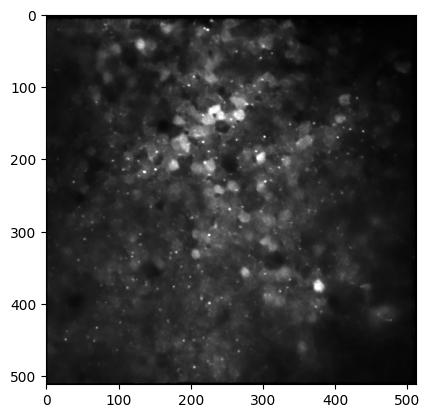

In [7]:
plt.imshow(mov[1000], cmap="gray", vmin=0, vmax=255)

In [8]:
export_movie_with_scalebar(mov, output_path=os.path.join(tmpdir, "20241018_rec11.mp4"), fps=int(15.4*4),
                           pixel_size_um=0.52, scalebar_um=50, font_size=15)

Video saved to /flash/ReiterU/tmp/tomo_CPHVMVEELMBT/20241018_rec11.mp4


In [9]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1"
print(f"mkdir {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
cp -r /flash/ReiterU/tmp/tomo_CPHVMVEELMBT/* /bucket/ReiterU/OLdev/analysis/20250419_sup_movies_1
